49.42625
50.0


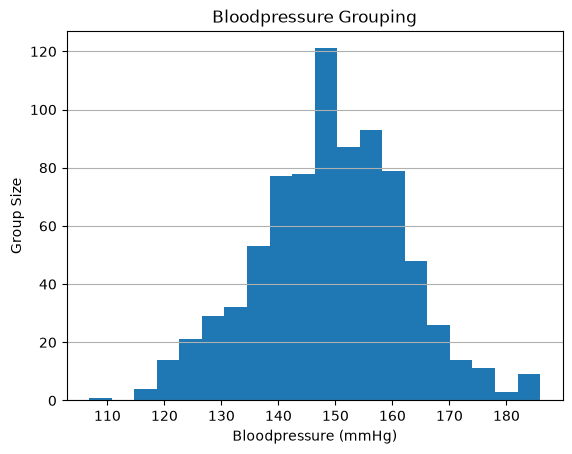

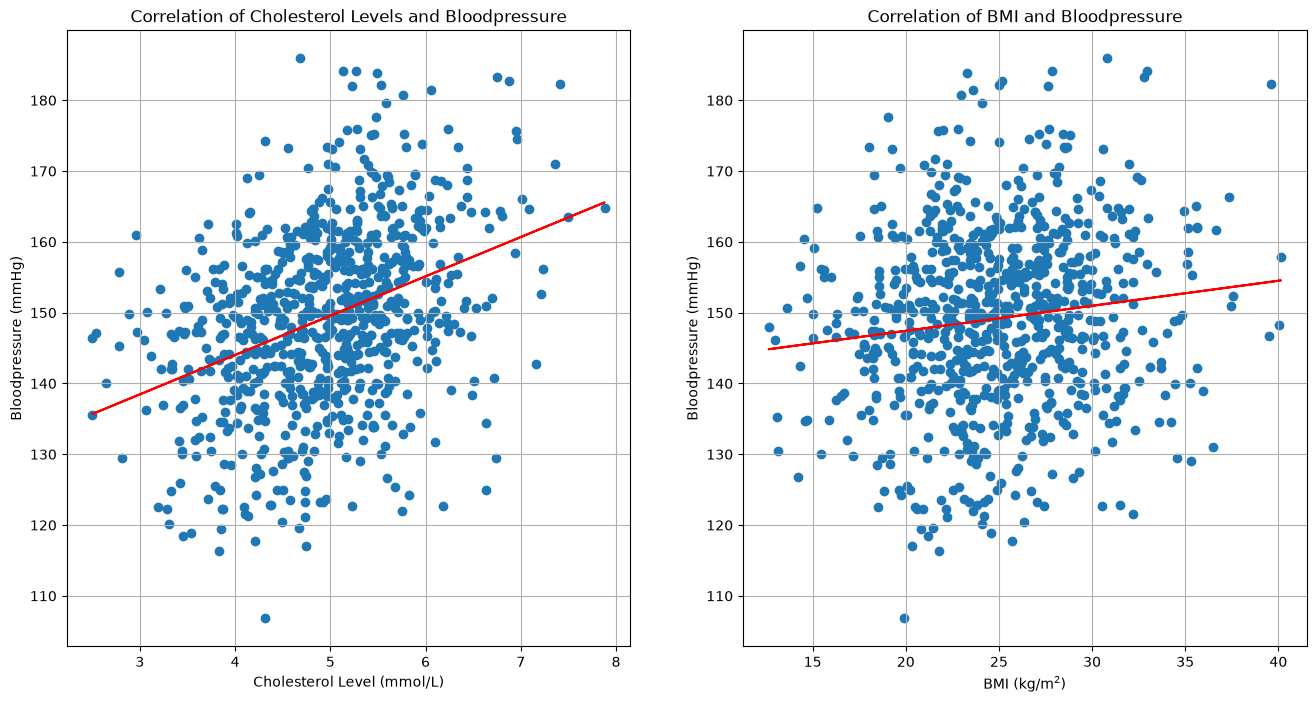

    id  age sex  height  weight  systolic_bp  cholesterol  smoker  disease
0    1   57   F   168.9    65.8        141.8         4.58       0        0
2    3   59   F   169.9    82.2        151.7         6.16       0        0
5    6   46   F   167.6    68.6        153.8         4.91       0        0
9   10   58   F   157.1    67.3        159.8         5.38       0        0
10  11   43   F   156.6    74.0        144.3         4.30       0        0
7    8   61   F   168.1    51.5        134.8         5.13       1        0
20  21   71   F   163.8    83.4        163.7         4.83       1        1
25  26   51   F   166.7    87.5        142.2         5.31       1        0
32  33   49   F   156.4    86.0        158.5         5.78       1        0
42  43   48   F   167.2    72.0        157.8         4.58       1        0
3    4   72   M   157.7    93.1        151.0         6.63       0        0
4    5   46   M   192.6   104.1        144.1         5.21       0        0
6    7   73   M   185.8  

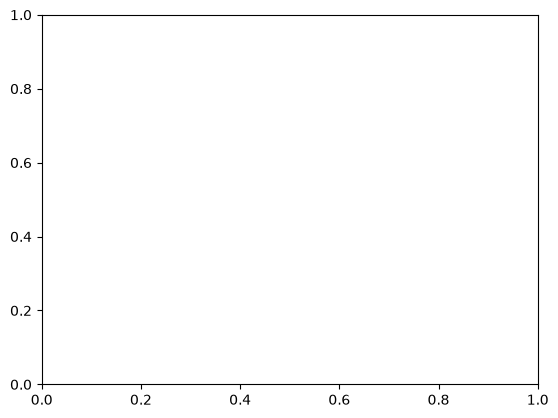

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from src import io_functions, viz
from src.viz import GraphTexts

raw = pd.read_csv("data/health_study_dataset.csv")
df = io_functions.clean_data(raw)

print(io_functions.mean(df["age"]))
print(io_functions.median(df["age"]))

fig, ax = plt.subplots()
viz.hist(ax,
         df["systolic_bp"],
		 20,
		 GraphTexts("Bloodpressure Grouping",
		 "Bloodpressure (mmHg)",
		 "Group Size"))
plt.show()

fig, axs = plt.subplots(1, 2, figsize=[16, 8])
viz.scatter(axs[0],
            df["cholesterol"],
			df["systolic_bp"],
			GraphTexts("Correlation of Cholesterol Levels and Bloodpressure",
			           "Cholesterol Level (mmol/L)",
					   "Bloodpressure (mmHg)"),
			True)
bmi = df["weight"] / ((df["height"] / 100) ** 2)
viz.scatter(axs[1],
            bmi,
			df["systolic_bp"],
			GraphTexts("Correlation of BMI and Bloodpressure",
			           r"BMI (kg/m$^{2}$)",
					   "Bloodpressure (mmHg)"),
			True)
plt.show()

fig, ax = plt.subplots()
smokers_by_sex = df.sort_values(["sex", "smoker"]).groupby(["sex", "smoker"])
print(smokers_by_sex.head())